In [35]:
import os
print("Current Working Directory:", os.getcwd())
print("Data folder exists?", os.path.exists('./data'))

Current Working Directory: c:\Users\User\OneDrive\Documents\GitHub\AI-ML-assessment-cifar10-project
Data folder exists? True


In [36]:
import os
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

In [37]:
data_dir = r"C:\Users\User\OneDrive\Documents\GitHub\AI-ML-assessment-cifar10-project\data"
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])


In [38]:
train_val_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_size = 45000
val_size = 5000
train_dataset, val_dataset = random_split(train_val_dataset, [train_size, val_size])

In [39]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Classes: {train_val_dataset.classes}")
print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training samples: 45000
Validation samples: 5000
Test samples: 10000


In [40]:
!pip install matplotlib

In [41]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [42]:
class SimpleMLP(nn.Module):
    def __init__(self, input_dim=32*32*3, hidden_dim=512, output_dim=10):
        super(SimpleMLP, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)
        self.fc2 = nn.Linear(hidden_dim, 256)
        self.fc3 = nn.Linear(256, output_dim)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SimpleMLP().to(device)

In [43]:
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {total_params:,}")

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

Total Trainable Parameters: 1,707,274


In [44]:
num_epochs = 10
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

In [47]:
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = correct / total
    history['train_loss'].append(epoch_loss)
    history['train_acc'].append(epoch_acc)

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_epoch_loss = val_loss / len(val_loader.dataset)
    val_epoch_acc = val_correct / val_total
    history['val_loss'].append(val_epoch_loss)
    history['val_acc'].append(val_epoch_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}], "
          f"Train Loss: {epoch_loss:.4f}, Train Acc: {epoch_acc:.4f}, "
          f"Val Loss: {val_epoch_loss:.4f}, Val Acc: {val_epoch_acc:.4f}")

Epoch [1/10], Train Loss: 1.6806, Train Acc: 0.4058, Val Loss: 1.5636, Val Acc: 0.4524
Epoch [2/10], Train Loss: 1.4961, Train Acc: 0.4688, Val Loss: 1.4665, Val Acc: 0.4822
Epoch [3/10], Train Loss: 1.4063, Train Acc: 0.5048, Val Loss: 1.4481, Val Acc: 0.4900
Epoch [4/10], Train Loss: 1.3394, Train Acc: 0.5271, Val Loss: 1.4059, Val Acc: 0.5158
Epoch [5/10], Train Loss: 1.2819, Train Acc: 0.5461, Val Loss: 1.3963, Val Acc: 0.5134
Epoch [6/10], Train Loss: 1.2254, Train Acc: 0.5634, Val Loss: 1.3945, Val Acc: 0.5252
Epoch [7/10], Train Loss: 1.1778, Train Acc: 0.5832, Val Loss: 1.3776, Val Acc: 0.5290
Epoch [8/10], Train Loss: 1.1314, Train Acc: 0.5974, Val Loss: 1.3733, Val Acc: 0.5308
Epoch [9/10], Train Loss: 1.0833, Train Acc: 0.6158, Val Loss: 1.4204, Val Acc: 0.5304
Epoch [10/10], Train Loss: 1.0464, Train Acc: 0.6319, Val Loss: 1.4327, Val Acc: 0.5256


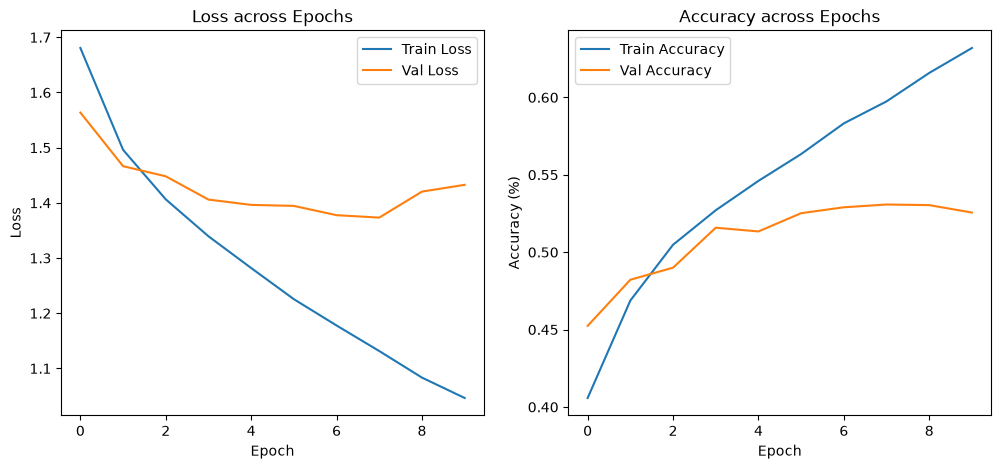

In [48]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.title('Loss across Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Accuracy')
plt.plot(history['val_acc'], label='Val Accuracy')
plt.title('Accuracy across Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.show()

In [50]:
!pip install scikit-learn seaborn


   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 1.7 MB/s eta 0:00:05
   --- ------------------------------------ 0.8/8.4 MB 1.9 MB/s eta 0:00:04
   ----- ---------------------------------- 1.0/8.4 MB 1.5 MB/s eta 0:00:05
   ------- -------------------------------- 1.6/8.4 MB 1.8 MB/s eta 0:00:04
   ---------- ----------------------------- 2.1/8.4 MB 1.9 MB/s eta 0:00:04
   ------------- -------------------------- 2.9/8.4 MB 2.2 MB/s eta 0:00:03
   ---------------- ----------------------- 3.4/8.4 MB 2.3 MB/s eta 0:00:03
   -------------------- ------------------- 4.2/8.4 MB 2.5 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.4 MB 2.5 MB/s eta 0:00:02
   ---------------------- ----------------- 4.7/8.4 MB 2.4 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.4 MB 2.2 MB/s eta 0:00:02
   -----------------------

In [51]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np

In [52]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [54]:
print("Classification Report:")
print(classification_report(all_labels, all_preds, target_names=test_dataset.classes))

Classification Report:
              precision    recall  f1-score   support

    airplane       0.65      0.52      0.58      1000
  automobile       0.61      0.65      0.63      1000
        bird       0.41      0.47      0.44      1000
         cat       0.34      0.44      0.38      1000
        deer       0.51      0.38      0.44      1000
         dog       0.43      0.36      0.39      1000
        frog       0.54      0.64      0.58      1000
       horse       0.68      0.54      0.60      1000
        ship       0.61      0.67      0.64      1000
       truck       0.56      0.59      0.57      1000

    accuracy                           0.53     10000
   macro avg       0.53      0.53      0.53     10000
weighted avg       0.53      0.53      0.53     10000



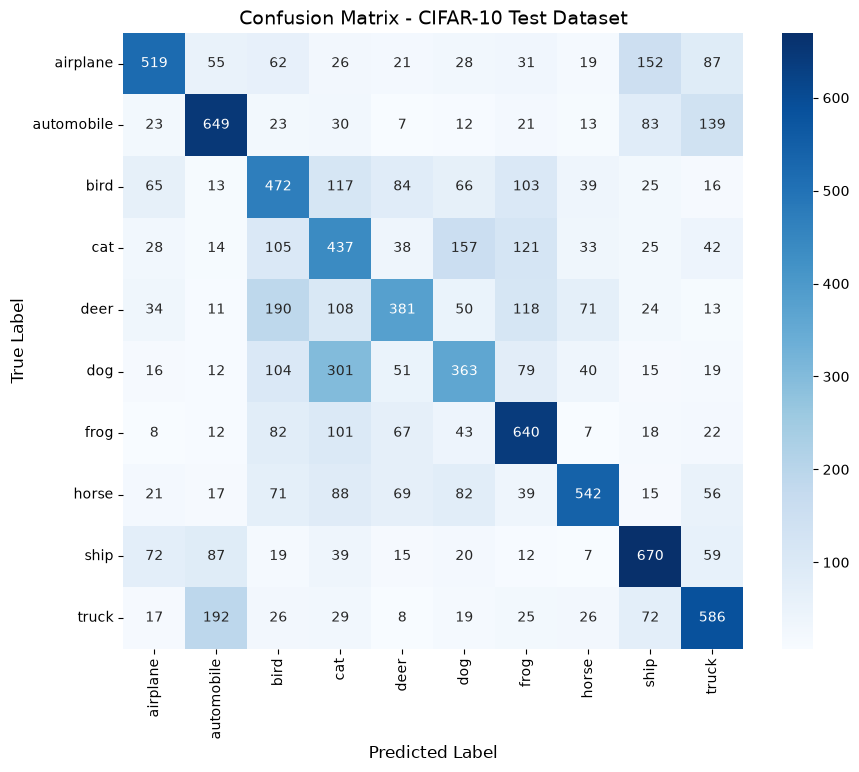

In [55]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=test_dataset.classes, 
            yticklabels=test_dataset.classes)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - CIFAR-10 Test Dataset', fontsize=14)
plt.show()

## 1. Introduction & Dataset Preparation
- **Dataset:** CIFAR-10 (32x32 color images across 10 classes).
- **Data Splitting:** Divided the 50,000 training images into 45,000 training samples and 5,000 validation samples using PyTorch's `random_split` to monitor overfitting during training.
- **Preprocessing:** Applied standard tensor conversion and normalization (mean=0.5, std=0.5) across all RGB channels.

## 2. Model Architecture (`SimpleMLP`)
- **Flatten Layer:** Reshapes the 3D image tensor ($3 \times 32 \times 32$) into a flat feature vector of dimension 3,072.
- **Hidden Layers:** 
  - Fully Connected Layer 1: $3072 \rightarrow 512$ with ReLU activation and Dropout ($p=0.2$) for regularization.
  - Fully Connected Layer 2: $512 \rightarrow 256$ with ReLU activation.
  - Output Layer: $256 \rightarrow 10$ (logits for the 10 respective classes).
- **Optimizer & Loss:** Trained using the Adam optimizer ($\text{lr}=0.001$) and Cross-Entropy Loss function.

## 3. Results & Evaluation Analysis
- **Training Dynamics:** The loss and accuracy curves across 10 epochs demonstrate steady convergence. (You can briefly mention how train vs. val accuracy compares here).
- **Confusion Matrix Insights:** The confusion matrix highlights which classes the MLP model struggles with most (e.g., visually similar classes like cats and dogs or automobiles and trucks, which is common for standard MLPs lacking spatial convolutional filters).